# TUSZ patient eligibility analysis for ictal detection and exploratory preictal warning

This notebook defines **outcome-independent patient eligibility** for the external TUSZ evaluation. Patient selection is based only on recording availability, seizure annotations, montage availability, and the amount of clean interictal EEG available for patient-specific training, validation, and held-out testing. No EEG-CASCADE, Rössler, Bowen--Dinaburg entropy, or seizure-detection performance is used to select patients.

Two analysis cohorts are defined separately because the data requirements differ:

- **Ictal external-validation cohort:** at least 10 usable 30-s seizure-onset windows, at least 20 clean 30-s interictal training windows, at least 10 validation windows, and at least 10 held-out interictal test windows.
- **Exploratory preictal cohort:** at least 5 usable preictal events in the selected $-4$ to $-2$ min interval (SPH = 2 min, SOP = 2 min), at least 20 clean 2-min interictal training sequences, at least 10 validation sequences, and at least 10 held-out interictal test sequences.

The cohorts are intentionally **not forced to be identical**. Requiring the same patients for both experiments would discard eligible data and would make ictal eligibility depend on preictal recording availability. The overlap between cohorts is reported explicitly.


## 1. Configuration


In [1]:
# ================================================================
# TUSZ PATIENT ELIGIBILITY ANALYSIS
# Ictal + several preictal SPH/SOP definitions
# ================================================================

from pathlib import Path
from collections import defaultdict
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", None)

# ------------------------------------------------------------
# DATA
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6"
)

OUT_DIR = Path("tusz_patient_eligibility_analysis")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Montage
# ------------------------------------------------------------

COMMON16 = [
    "FP1-F7", "F7-T7", "T7-P7", "P7-O1",
    "FP1-F3", "F3-C3", "C3-P3", "P3-O1",
    "FP2-F4", "F4-C4", "C4-P4", "P4-O2",
    "FP2-F8", "F8-T8", "T8-P8", "P8-O2",
]

# ------------------------------------------------------------
# Ictal definition
# ------------------------------------------------------------

ICTAL_WINDOW_SECONDS = 30.0

# For clean interictal data in the ictal experiment
ICTAL_SEIZURE_BUFFER_SECONDS = 120.0

# ------------------------------------------------------------
# Preictal configurations
#
# SOP = seizure occurrence period
# SPH = seizure prediction horizon
#
# preictal interval:
# -(SOP + SPH) to -SPH
# ------------------------------------------------------------

PREICTAL_CONFIGS = [
    {
        "name": "sop10_sph2",
        "sop_min": 10.0,
        "sph_min": 2.0,
    },
    {
        "name": "sop5_sph2",
        "sop_min": 5.0,
        "sph_min": 2.0,
    },
    {
        "name": "sop2_sph2",
        "sop_min": 2.0,
        "sph_min": 2.0,
    },
]

# Same post-seizure exclusion used in the current short-preictal design
PREICTAL_POST_BUFFER_SECONDS = 120.0

# Match current patient-specific split principle
TRAIN_FRACTION = 0.50
VAL_FRACTION = 0.25

# Current pipeline caps clean interictal scans
MAX_INTERICTAL_SCANS = 200

## 2. Annotation, path, and montage helpers


In [2]:
# ================================================================
# HELPERS
# ================================================================

SEIZURE_LABELS = {
    "seiz", "fnsz", "gnsz", "spsz", "cpsz", "absz",
    "tnsz", "tcsz", "mysz", "atsz", "clsz", "seizure",
}


def norm_ch(name):
    s = str(name).upper().strip()

    s = s.replace("EEG", "")
    s = s.replace(" ", "").replace("_", "").replace(".", "")

    s = s.replace("-LE", "")
    s = s.replace("-REF", "")
    s = s.replace("REF", "")

    s = re.sub(r"-\d+$", "", s)

    # legacy temporal electrode names
    s = (
        s.replace("T3", "T7")
         .replace("T4", "T8")
         .replace("T5", "P7")
         .replace("T6", "P8")
    )

    return s.strip("-")


def parse_tusz_path(p):
    """
    Expected structure contains:
        .../edf/<split>/<patient>/<session>/<montage>/<file>.edf
    """

    parts = p.parts

    out = {
        "split": "unknown",
        "patient": "unknown",
        "session": "unknown",
        "montage": "unknown",
    }

    if "edf" in parts:
        i = parts.index("edf")

        if len(parts) > i + 5:
            out["split"] = parts[i + 1]
            out["patient"] = parts[i + 2]
            out["session"] = parts[i + 3]
            out["montage"] = parts[i + 4]

    return out


def annotation_candidates(edf_path):
    stem = edf_path.with_suffix("")

    return [
        Path(str(stem) + ".csv_bi"),
        Path(str(stem) + ".csv"),
    ]


def read_tusz_annotation(path):
    cols = [
        "channel",
        "start_time",
        "stop_time",
        "label",
        "confidence",
    ]

    if (not path.exists()) or path.stat().st_size == 0:
        return pd.DataFrame(columns=cols)

    rows = []

    with open(path, "r", errors="ignore") as f:

        for line in f:

            line = line.strip()

            if not line or line.startswith("#"):
                continue

            parts = [x.strip() for x in line.split(",")]

            if len(parts) < 4:
                continue

            joined = ",".join(parts).lower()

            if (
                "channel" in joined
                and "start" in joined
                and "stop" in joined
            ):
                continue

            start = pd.to_numeric(
                parts[1],
                errors="coerce",
            )

            stop = pd.to_numeric(
                parts[2],
                errors="coerce",
            )

            if pd.isna(start) or pd.isna(stop):
                continue

            rows.append(
                {
                    "channel": parts[0],
                    "start_time": float(start),
                    "stop_time": float(stop),
                    "label": str(parts[3]).strip().lower(),
                    "confidence": (
                        pd.to_numeric(parts[4], errors="coerce")
                        if len(parts) >= 5
                        else np.nan
                    ),
                }
            )

    return pd.DataFrame(rows, columns=cols)


def is_seizure_label(x):
    x = str(x).lower().strip()

    return (
        x in SEIZURE_LABELS
        or "seiz" in x
        or x.endswith("sz")
    )


def common16_available(ch_names):
    """
    True when every required common16 bipolar channel can be
    obtained either directly or from its two referential channels.
    """

    lookup = {}

    for ch in ch_names:
        key = norm_ch(ch)

        if key and key not in lookup:
            lookup[key] = ch

    missing = []

    for pair in COMMON16:

        pair_key = norm_ch(pair)
        a, b = pair_key.split("-")

        direct = pair_key in lookup
        reconstructable = (a in lookup) and (b in lookup)

        if not (direct or reconstructable):
            missing.append(pair)

    return len(missing) == 0, missing

## 3. Index TUSZ recordings and seizure annotations

EDF files are opened with `preload=False`; only recording metadata and channel names are read at this stage.


In [3]:
# ================================================================
# INDEX ALL TUSZ EDF FILES
#
# preload=False:
# we only obtain duration + channel names
# ================================================================

edf_files = sorted(DATA_ROOT.rglob("*.edf"))

print("EDF files found:", len(edf_files))

edf_rows = []
seizure_rows = []
read_errors = []

for k, edf in enumerate(edf_files, start=1):

    if k % 500 == 0:
        print(f"Processed {k}/{len(edf_files)} EDFs")

    meta = parse_tusz_path(edf)

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            raw = mne.io.read_raw_edf(
                str(edf),
                preload=False,
                verbose="ERROR",
            )

        sfreq = float(raw.info["sfreq"])
        duration = float(raw.n_times / sfreq)

        montage_ok, missing_channels = common16_available(
            raw.ch_names
        )

        raw.close()

    except Exception as exc:

        read_errors.append(
            {
                "edf": str(edf),
                "patient": meta["patient"],
                "error": repr(exc),
            }
        )

        continue

    # ------------------------------------------------------------
    # annotation
    # ------------------------------------------------------------

    ann = None
    ann_path = None

    for candidate in annotation_candidates(edf):

        if candidate.exists():

            tmp = read_tusz_annotation(candidate)

            if len(tmp):

                seizure_part = tmp[
                    tmp["label"].apply(is_seizure_label)
                ].dropna(
                    subset=["start_time", "stop_time"]
                )

                if len(seizure_part):
                    ann = seizure_part.copy()
                    ann_path = candidate
                    break

    # ------------------------------------------------------------
    # EDF table
    # ------------------------------------------------------------

    edf_rows.append(
        {
            "edf": str(edf),
            "patient": meta["patient"],
            "split": meta["split"],
            "session": meta["session"],
            "montage": meta["montage"],
            "duration_sec": duration,
            "sfreq": sfreq,
            "common16_ok": bool(montage_ok),
            "missing_common16": ";".join(missing_channels),
            "annotation_file": (
                str(ann_path) if ann_path is not None else ""
            ),
        }
    )

    # ------------------------------------------------------------
    # Collapse duplicate channel-level seizure annotations
    # ------------------------------------------------------------

    if ann is not None and len(ann):

        events = (
            ann.groupby(
                ["start_time", "stop_time", "label"],
                as_index=False,
            )
            .size()
            .sort_values(
                ["start_time", "stop_time"]
            )
        )

        for j, r in events.iterrows():

            onset = float(r["start_time"])
            offset = float(r["stop_time"])

            if offset <= onset:
                continue

            seizure_rows.append(
                {
                    "patient": meta["patient"],
                    "edf": str(edf),
                    "split": meta["split"],
                    "session": meta["session"],
                    "montage": meta["montage"],
                    "onset_sec": onset,
                    "offset_sec": offset,
                    "duration_sec": offset - onset,
                    "label": str(r["label"]),
                    "common16_ok": bool(montage_ok),
                    "edf_duration_sec": duration,
                }
            )


edf_df = pd.DataFrame(edf_rows)
seizure_df = pd.DataFrame(seizure_rows)
error_df = pd.DataFrame(read_errors)

print()
print("Indexed EDFs:", len(edf_df))
print("Seizure events:", len(seizure_df))
print("Patients with EDFs:", edf_df["patient"].nunique())
print("Patients with >=1 seizure:", seizure_df["patient"].nunique())
print("EDF read errors:", len(error_df))

edf_df.to_csv(
    OUT_DIR / "tusz_edf_index.csv",
    index=False,
)

seizure_df.to_csv(
    OUT_DIR / "tusz_seizure_index.csv",
    index=False,
)

error_df.to_csv(
    OUT_DIR / "tusz_edf_read_errors.csv",
    index=False,
)

EDF files found: 8140
Processed 500/8140 EDFs
Processed 1000/8140 EDFs
Processed 1500/8140 EDFs
Processed 2000/8140 EDFs
Processed 2500/8140 EDFs
Processed 3000/8140 EDFs
Processed 3500/8140 EDFs
Processed 4000/8140 EDFs
Processed 4500/8140 EDFs
Processed 5000/8140 EDFs
Processed 5500/8140 EDFs
Processed 6000/8140 EDFs
Processed 6500/8140 EDFs
Processed 7000/8140 EDFs
Processed 7500/8140 EDFs
Processed 8000/8140 EDFs

Indexed EDFs: 8140
Seizure events: 2663
Patients with EDFs: 675
Patients with >=1 seizure: 238
EDF read errors: 0


## 4. Seizure burden across patients


In [4]:
# ================================================================
# SEIZURE BURDEN PER PATIENT
# ================================================================

seizure_counts = (
    seizure_df
    .groupby("patient")
    .size()
    .rename("n_seizures")
    .reset_index()
    .sort_values(
        "n_seizures",
        ascending=False,
    )
)

print(
    "Patients with at least one annotated seizure:",
    len(seizure_counts)
)

display(seizure_counts.head(10))

seizure_counts.to_csv(
    OUT_DIR / "patient_seizure_counts.csv",
    index=False,
)

Patients with at least one annotated seizure: 238


,patient,n_seizures
177,aaaaapks,148
197,aaaaaqtx,129
68,aaaaahie,96
101,aaaaajqo,89
93,aaaaajdn,78
105,aaaaajru,75
172,aaaaaovk,69
202,aaaaardk,60
16,aaaaabhz,60
142,aaaaampk,59


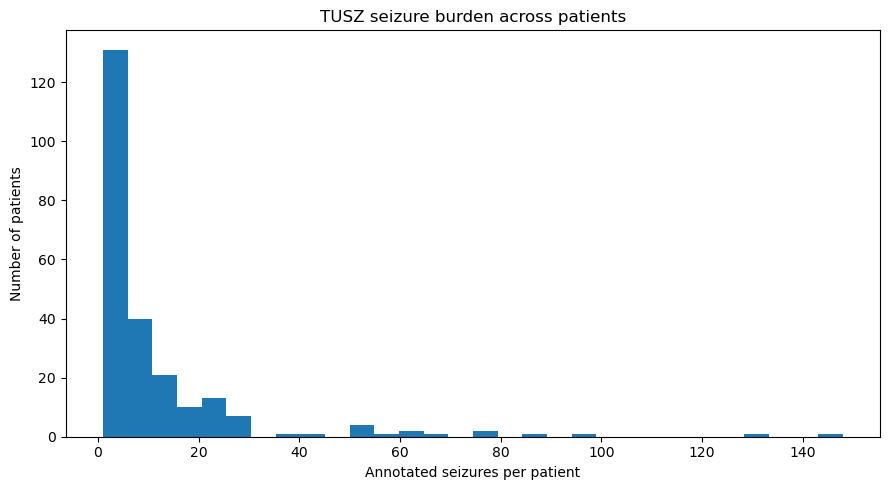

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    seizure_counts["n_seizures"],
    bins=30
)

ax.set_xlabel("Annotated seizures per patient")
ax.set_ylabel("Number of patients")
ax.set_title("TUSZ seizure burden across patients")

fig.tight_layout()
plt.show()

In [6]:
for n in [1, 2, 3, 5, 10, 20, 30, 40, 50]:

    print(
        f">= {n:2d} seizures:",
        int((seizure_counts["n_seizures"] >= n).sum()),
        "patients"
    )

>=  1 seizures: 238 patients
>=  2 seizures: 173 patients
>=  3 seizures: 144 patients
>=  5 seizures: 114 patients
>= 10 seizures: 74 patients
>= 20 seizures: 36 patients
>= 30 seizures: 16 patients
>= 40 seizures: 15 patients
>= 50 seizures: 14 patients


## 2. Annotation, path, and montage helpers


In [7]:
# ================================================================
# INTERVAL HELPERS
# ================================================================

def merge_intervals(intervals):

    intervals = sorted(
        [
            (float(a), float(b))
            for a, b in intervals
            if b > a
        ]
    )

    if not intervals:
        return []

    merged = [list(intervals[0])]

    for a, b in intervals[1:]:

        if a <= merged[-1][1]:
            merged[-1][1] = max(
                merged[-1][1],
                b,
            )

        else:
            merged.append([a, b])

    return [
        (float(a), float(b))
        for a, b in merged
    ]


def clean_intervals(
    duration,
    seizures,
    pre_buffer,
    post_buffer,
):

    blocked = []

    for onset, offset in seizures:

        blocked.append(
            (
                max(0.0, onset - pre_buffer),
                min(
                    duration,
                    offset + post_buffer,
                ),
            )
        )

    blocked = merge_intervals(blocked)

    clean = []

    cur = 0.0

    for a, b in blocked:

        if a > cur:
            clean.append((cur, a))

        cur = max(cur, b)

    if cur < duration:
        clean.append((cur, duration))

    return clean


def count_nonoverlapping_windows(
    intervals,
    window_seconds,
):

    n = 0

    for a, b in intervals:

        length = max(0.0, b - a)

        n += int(
            math.floor(
                (length + 1e-9)
                / window_seconds
            )
        )

    return n


def split_counts(n):

    n = int(n)

    if n <= 0:
        return 0, 0, 0

    n_train = int(
        round(TRAIN_FRACTION * n)
    )

    n_val = int(
        round(VAL_FRACTION * n)
    )

    n_train = max(1, n_train)

    if n - n_train > 0:
        n_val = max(1, n_val)
    else:
        n_val = 0

    n_test = max(
        0,
        n - n_train - n_val
    )

    return (
        n_train,
        n_val,
        n_test,
    )


def overlaps_other_seizure(
    start,
    end,
    target_index,
    seizures,
):

    for j, (onset, offset) in enumerate(seizures):

        if j == target_index:
            continue

        if max(start, onset) < min(end, offset):
            return True

    return False

## 6. Compute patient-level ictal, preictal, and matched interictal availability


In [8]:
# ================================================================
# PATIENT ELIGIBILITY
# ================================================================

patients = sorted(
    seizure_df["patient"].dropna().unique()
)

summary_rows = []

for patient in patients:

    patient_edfs = edf_df[
        edf_df["patient"] == patient
    ].copy()

    patient_sz = seizure_df[
        seizure_df["patient"] == patient
    ].copy()

    row = {
        "patient": patient,
        "n_seizures_total": len(patient_sz),
        "n_edfs": len(patient_edfs),
        "n_common16_edfs": int(
            patient_edfs["common16_ok"].sum()
        ),
    }

    # ============================================================
    # ICTAL
    # ============================================================

    usable_ictal = 0
    ictal_interictal_windows = 0

    for _, edf_row in patient_edfs.iterrows():

        if not bool(edf_row["common16_ok"]):
            continue

        edf_path = edf_row["edf"]
        duration = float(edf_row["duration_sec"])

        sz_here = patient_sz[
            patient_sz["edf"] == edf_path
        ].sort_values("onset_sec")

        seizures_here = [
            (
                float(r["onset_sec"]),
                float(r["offset_sec"]),
            )
            for _, r in sz_here.iterrows()
        ]

        # usable 30-s seizure-onset windows
        for onset, offset in seizures_here:

            if (
                onset >= 0
                and onset + ICTAL_WINDOW_SECONDS
                <= duration + 1e-6
            ):
                usable_ictal += 1

        # clean same-length interictal windows
        clean = clean_intervals(
            duration=duration,
            seizures=seizures_here,
            pre_buffer=ICTAL_SEIZURE_BUFFER_SECONDS,
            post_buffer=ICTAL_SEIZURE_BUFFER_SECONDS,
        )

        ictal_interictal_windows += (
            count_nonoverlapping_windows(
                clean,
                ICTAL_WINDOW_SECONDS,
            )
        )

    ictal_interictal_model = min(
        ictal_interictal_windows,
        MAX_INTERICTAL_SCANS,
    )

    tr, va, te = split_counts(
        ictal_interictal_model
    )

    row["ictal_usable_30s"] = usable_ictal

    row[
        "ictal_interictal_30s_raw"
    ] = ictal_interictal_windows

    row[
        "ictal_interictal_30s_model"
    ] = ictal_interictal_model

    row["ictal_train_interictal"] = tr
    row["ictal_val_interictal"] = va
    row["ictal_test_interictal"] = te

    row["ictal_basic_eligible"] = bool(
        usable_ictal >= 1
        and tr >= 1
        and va >= 1
        and te >= 1
    )

    # ============================================================
    # PREICTAL CONFIGURATIONS
    # ============================================================

    for cfg in PREICTAL_CONFIGS:

        name = cfg["name"]

        sop_min = float(cfg["sop_min"])
        sph_min = float(cfg["sph_min"])

        # Example:
        # SOP=10, SPH=2
        # start = onset - 12 min
        # end   = onset - 2 min

        start_before = (
            sop_min + sph_min
        ) * 60.0

        end_before = sph_min * 60.0

        positive_length = sop_min * 60.0

        usable_preictal = 0
        matching_interictal = 0

        for _, edf_row in patient_edfs.iterrows():

            if not bool(edf_row["common16_ok"]):
                continue

            edf_path = edf_row["edf"]
            duration = float(
                edf_row["duration_sec"]
            )

            sz_here = patient_sz[
                patient_sz["edf"] == edf_path
            ].sort_values("onset_sec")

            seizures_here = [
                (
                    float(r["onset_sec"]),
                    float(r["offset_sec"]),
                )
                for _, r in sz_here.iterrows()
            ]

            # ----------------------------------------------------
            # positive preictal windows
            # ----------------------------------------------------

            for j, (onset, offset) in enumerate(
                seizures_here
            ):

                pst = onset - start_before
                pen = onset - end_before

                if pst < 0:
                    continue

                if pen > duration:
                    continue

                if (
                    pen - pst
                    < positive_length - 1e-6
                ):
                    continue

                # Require full candidate preictal + SPH region
                # to be uncontaminated by another seizure.
                if overlaps_other_seizure(
                    start=pst,
                    end=onset,
                    target_index=j,
                    seizures=seizures_here,
                ):
                    continue

                usable_preictal += 1

            # ----------------------------------------------------
            # same-duration clean interictal windows
            # ----------------------------------------------------

            clean = clean_intervals(
                duration=duration,
                seizures=seizures_here,

                # exclude the entire preictal + SPH region
                pre_buffer=start_before,

                post_buffer=PREICTAL_POST_BUFFER_SECONDS,
            )

            matching_interictal += (
                count_nonoverlapping_windows(
                    clean,
                    positive_length,
                )
            )

        model_n = min(
            matching_interictal,
            MAX_INTERICTAL_SCANS,
        )

        tr, va, te = split_counts(model_n)

        row[
            f"{name}_preictal_events"
        ] = usable_preictal

        row[
            f"{name}_interictal_raw"
        ] = matching_interictal

        row[
            f"{name}_interictal_model"
        ] = model_n

        row[
            f"{name}_train_interictal"
        ] = tr

        row[
            f"{name}_val_interictal"
        ] = va

        row[
            f"{name}_test_interictal"
        ] = te

        # BASIC structural eligibility only.
        # We deliberately do NOT impose an arbitrary minimum
        # number of preictal seizures here.
        row[
            f"{name}_basic_eligible"
        ] = bool(
            usable_preictal >= 1
            and tr >= 1
            and va >= 1
            and te >= 1
        )

    summary_rows.append(row)


eligibility = pd.DataFrame(summary_rows)

eligibility = eligibility.sort_values(
    "n_seizures_total",
    ascending=False,
).reset_index(drop=True)

display(eligibility.head(10))

eligibility.to_csv(
    OUT_DIR / "tusz_patient_eligibility_master.csv",
    index=False,
)

,patient,n_seizures_total,n_edfs,n_common16_edfs,ictal_usable_30s,ictal_interictal_30s_raw,ictal_interictal_30s_model,ictal_train_interictal,ictal_val_interictal,ictal_test_interictal,ictal_basic_eligible,sop10_sph2_preictal_events,sop10_sph2_interictal_raw,sop10_sph2_interictal_model,sop10_sph2_train_interictal,sop10_sph2_val_interictal,sop10_sph2_test_interictal,sop10_sph2_basic_eligible,sop5_sph2_preictal_events,sop5_sph2_interictal_raw,sop5_sph2_interictal_model,sop5_sph2_train_interictal,sop5_sph2_val_interictal,sop5_sph2_test_interictal,sop5_sph2_basic_eligible,sop2_sph2_preictal_events,sop2_sph2_interictal_raw,sop2_sph2_interictal_model,sop2_sph2_train_interictal,sop2_sph2_val_interictal,sop2_sph2_test_interictal,sop2_sph2_basic_eligible
0,aaaaapks,148,97,97,142,1410,200,100,50,50,True,0,50,50,25,12,13,False,1,132,132,66,33,33,True,4,329,200,100,50,50,True
1,aaaaaqtx,129,53,53,123,1273,200,100,50,50,True,0,59,59,30,15,14,False,0,125,125,62,31,32,False,0,313,200,100,50,50,False
2,aaaaahie,96,414,414,95,12781,200,100,50,50,True,14,560,200,100,50,50,True,30,1190,200,100,50,50,True,59,3079,200,100,50,50,True
3,aaaaajqo,89,74,74,85,2079,200,100,50,50,True,0,91,91,46,23,22,False,1,188,188,94,47,47,True,10,498,200,100,50,50,True
4,aaaaajdn,78,9,9,76,0,0,0,0,0,False,0,0,0,0,0,0,False,0,0,0,0,0,0,False,1,0,0,0,0,0,False
5,aaaaajru,75,49,49,72,393,200,100,50,50,True,0,10,10,5,2,3,False,1,32,32,16,8,8,True,8,82,82,41,20,21,True
6,aaaaaovk,69,3,3,69,45,45,22,11,12,True,0,2,2,1,1,0,False,0,4,4,2,1,1,False,0,11,11,6,3,2,False
7,aaaaardk,60,66,66,60,1028,200,100,50,50,True,1,16,16,8,4,4,True,11,45,45,22,11,12,True,54,170,170,85,42,43,True
8,aaaaabhz,60,37,37,60,98,98,49,24,25,True,0,2,2,1,1,0,False,0,8,8,4,2,2,False,0,20,20,10,5,5,False
9,aaaaampk,59,48,48,56,766,200,100,50,50,True,1,11,11,6,3,2,True,23,45,45,22,11,12,True,39,127,127,64,32,31,True


In [9]:
# ================================================================
# COMPACT PATIENT TABLE
# ================================================================

compact_cols = [
    "patient",
    "n_seizures_total",

    "ictal_usable_30s",
    "ictal_interictal_30s_model",
    "ictal_train_interictal",
    "ictal_val_interictal",
    "ictal_test_interictal",

    "sop10_sph2_preictal_events",
    "sop10_sph2_interictal_model",

    "sop5_sph2_preictal_events",
    "sop5_sph2_interictal_model",

    "sop2_sph2_preictal_events",
    "sop2_sph2_interictal_model",
]

compact = eligibility[compact_cols].copy()

display(compact.head(10))

compact.to_csv(
    OUT_DIR / "tusz_patient_eligibility_compact.csv",
    index=False,
)

,patient,n_seizures_total,ictal_usable_30s,ictal_interictal_30s_model,ictal_train_interictal,ictal_val_interictal,ictal_test_interictal,sop10_sph2_preictal_events,sop10_sph2_interictal_model,sop5_sph2_preictal_events,sop5_sph2_interictal_model,sop2_sph2_preictal_events,sop2_sph2_interictal_model
0,aaaaapks,148,142,200,100,50,50,0,50,1,132,4,200
1,aaaaaqtx,129,123,200,100,50,50,0,59,0,125,0,200
2,aaaaahie,96,95,200,100,50,50,14,200,30,200,59,200
3,aaaaajqo,89,85,200,100,50,50,0,91,1,188,10,200
4,aaaaajdn,78,76,0,0,0,0,0,0,0,0,1,0
5,aaaaajru,75,72,200,100,50,50,0,10,1,32,8,82
6,aaaaaovk,69,69,45,22,11,12,0,2,0,4,0,11
7,aaaaardk,60,60,200,100,50,50,1,16,11,45,54,170
8,aaaaabhz,60,60,98,49,24,25,0,2,0,8,0,20
9,aaaaampk,59,56,200,100,50,50,1,11,23,45,39,127


In [10]:
# ================================================================
# ICTAL EVENT DISTRIBUTION
# ================================================================

ictal_dist = (
    eligibility[
        [
            "patient",
            "n_seizures_total",
            "ictal_usable_30s",
            "ictal_interictal_30s_model",
            "ictal_train_interictal",
            "ictal_val_interictal",
            "ictal_test_interictal",
            "ictal_basic_eligible",
        ]
    ]
    .sort_values(
        "ictal_usable_30s",
        ascending=False,
    )
)

display(ictal_dist.head(10))

,patient,n_seizures_total,ictal_usable_30s,ictal_interictal_30s_model,ictal_train_interictal,ictal_val_interictal,ictal_test_interictal,ictal_basic_eligible
0,aaaaapks,148,142,200,100,50,50,True
1,aaaaaqtx,129,123,200,100,50,50,True
2,aaaaahie,96,95,200,100,50,50,True
3,aaaaajqo,89,85,200,100,50,50,True
4,aaaaajdn,78,76,0,0,0,0,False
5,aaaaajru,75,72,200,100,50,50,True
6,aaaaaovk,69,69,45,22,11,12,True
7,aaaaardk,60,60,200,100,50,50,True
8,aaaaabhz,60,60,98,49,24,25,True
9,aaaaampk,59,56,200,100,50,50,True


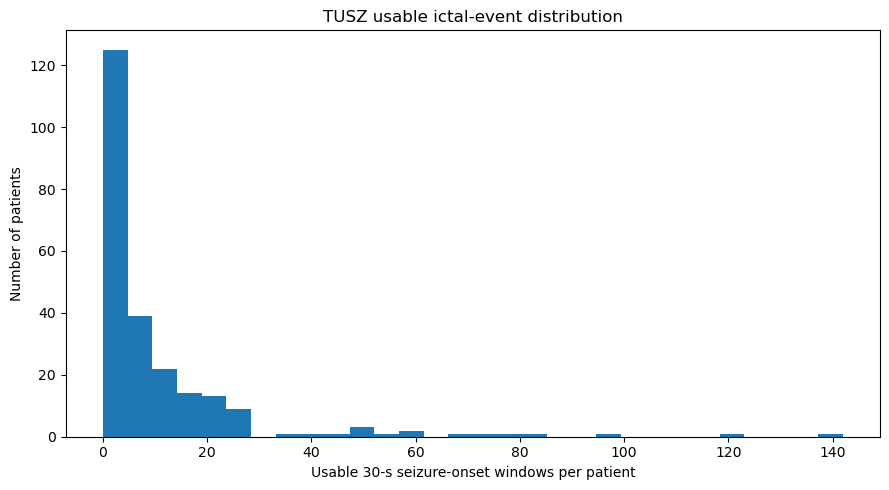

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    eligibility["ictal_usable_30s"],
    bins=30,
)

ax.set_xlabel(
    "Usable 30-s seizure-onset windows per patient"
)

ax.set_ylabel(
    "Number of patients"
)

ax.set_title(
    "TUSZ usable ictal-event distribution"
)

fig.tight_layout()
plt.show()

In [12]:
print("ICTAL PATIENT AVAILABILITY\n")

for n in [1, 2, 3, 5, 10, 15, 20, 30]:

    good = eligibility[
        (eligibility["ictal_usable_30s"] >= n)
        &
        (eligibility["ictal_train_interictal"] >= 1)
        &
        (eligibility["ictal_val_interictal"] >= 1)
        &
        (eligibility["ictal_test_interictal"] >= 1)
    ]

    print(
        f">= {n:2d} usable ictal events "
        f"+ valid interictal split: "
        f"{len(good)} patients"
    )

ICTAL PATIENT AVAILABILITY

>=  1 usable ictal events + valid interictal split: 229 patients
>=  2 usable ictal events + valid interictal split: 166 patients
>=  3 usable ictal events + valid interictal split: 139 patients
>=  5 usable ictal events + valid interictal split: 109 patients
>= 10 usable ictal events + valid interictal split: 72 patients
>= 15 usable ictal events + valid interictal split: 50 patients
>= 20 usable ictal events + valid interictal split: 35 patients
>= 30 usable ictal events + valid interictal split: 15 patients


In [13]:
# ================================================================
# PREICTAL AVAILABILITY
# ================================================================

for cfg in PREICTAL_CONFIGS:

    name = cfg["name"]

    sop = cfg["sop_min"]
    sph = cfg["sph_min"]

    start = sop + sph

    col = f"{name}_preictal_events"

    print()
    print("=" * 70)

    print(
        f"SOP={sop:g} min, SPH={sph:g} min "
        f"-> preictal interval -{start:g} to -{sph:g} min"
    )

    print("=" * 70)

    display(
        eligibility[
            [
                "patient",
                "n_seizures_total",
                col,
                f"{name}_interictal_model",
                f"{name}_train_interictal",
                f"{name}_val_interictal",
                f"{name}_test_interictal",
                f"{name}_basic_eligible",
            ]
        ]
        .sort_values(
            col,
            ascending=False,
        )
        .head(10)
    )


SOP=10 min, SPH=2 min -> preictal interval -12 to -2 min


,patient,n_seizures_total,sop10_sph2_preictal_events,sop10_sph2_interictal_model,sop10_sph2_train_interictal,sop10_sph2_val_interictal,sop10_sph2_test_interictal,sop10_sph2_basic_eligible
2,aaaaahie,96,14,200,100,50,50,True
46,aaaaarsp,15,5,73,36,18,19,True
34,aaaaarnq,21,2,1,1,0,0,False
17,aaaaardf,28,2,17,8,4,5,True
48,aaaaalfs,15,2,0,0,0,0,False
25,aaaaaskf,24,1,65,32,16,17,True
81,aaaaatgc,8,1,22,11,6,5,True
80,aaaaarcs,8,1,12,6,3,3,True
88,aaaaaopm,8,1,28,14,7,7,True
96,aaaaasip,7,1,13,6,3,4,True



SOP=5 min, SPH=2 min -> preictal interval -7 to -2 min


,patient,n_seizures_total,sop5_sph2_preictal_events,sop5_sph2_interictal_model,sop5_sph2_train_interictal,sop5_sph2_val_interictal,sop5_sph2_test_interictal,sop5_sph2_basic_eligible
2,aaaaahie,96,30,200,100,50,50,True
9,aaaaampk,59,23,45,22,11,12,True
7,aaaaardk,60,11,45,22,11,12,True
21,aaaaanme,26,7,200,100,50,50,True
46,aaaaarsp,15,7,158,79,40,39,True
17,aaaaardf,28,6,48,24,12,12,True
87,aaaaaoys,8,6,23,12,6,5,True
24,aaaaamqq,25,5,184,92,46,46,True
34,aaaaarnq,21,5,7,4,2,1,True
48,aaaaalfs,15,4,5,2,1,2,True



SOP=2 min, SPH=2 min -> preictal interval -4 to -2 min


,patient,n_seizures_total,sop2_sph2_preictal_events,sop2_sph2_interictal_model,sop2_sph2_train_interictal,sop2_sph2_val_interictal,sop2_sph2_test_interictal,sop2_sph2_basic_eligible
2,aaaaahie,96,59,200,100,50,50,True
7,aaaaardk,60,54,170,85,42,43,True
9,aaaaampk,59,39,127,64,32,31,True
17,aaaaardf,28,22,142,71,36,35,True
21,aaaaanme,26,20,200,100,50,50,True
14,aaaaaqkb,41,16,84,42,21,21,True
20,aaaaatez,26,15,45,22,11,12,True
56,aaaaaqld,14,13,118,59,30,29,True
46,aaaaarsp,15,11,200,100,50,50,True
3,aaaaajqo,89,10,200,100,50,50,True


## 7. Compare candidate preictal definitions

The three candidate definitions keep SPH fixed at 2 min and vary SOP: 10 min ($-12$ to $-2$), 5 min ($-7$ to $-2$), and 2 min ($-4$ to $-2$). These availability summaries are used only to determine whether a definition is practically analyzable in TUSZ.


In [14]:
# ================================================================
# PREICTAL ELIGIBILITY AT DIFFERENT EVENT THRESHOLDS
# ================================================================

threshold_rows = []

for cfg in PREICTAL_CONFIGS:

    name = cfg["name"]
    sop = cfg["sop_min"]
    sph = cfg["sph_min"]

    event_col = f"{name}_preictal_events"

    for min_events in [
        1, 2, 3, 5, 8, 10, 15, 20
    ]:

        mask = (
            (eligibility[event_col] >= min_events)
            &
            (
                eligibility[
                    f"{name}_train_interictal"
                ] >= 1
            )
            &
            (
                eligibility[
                    f"{name}_val_interictal"
                ] >= 1
            )
            &
            (
                eligibility[
                    f"{name}_test_interictal"
                ] >= 1
            )
        )

        threshold_rows.append(
            {
                "configuration": name,
                "SOP_min": sop,
                "SPH_min": sph,
                "preictal_interval": (
                    f"-{sop+sph:g} to -{sph:g} min"
                ),
                "minimum_preictal_events": min_events,
                "eligible_patients": int(mask.sum()),
            }
        )


threshold_table = pd.DataFrame(
    threshold_rows
)

display(threshold_table)

threshold_table.to_csv(
    OUT_DIR / "preictal_threshold_distribution.csv",
    index=False,
)

,configuration,SOP_min,SPH_min,preictal_interval,minimum_preictal_events,eligible_patients
0,sop10_sph2,10.0,2.0,-12 to -2 min,1,15
1,sop10_sph2,10.0,2.0,-12 to -2 min,2,3
2,sop10_sph2,10.0,2.0,-12 to -2 min,3,2
3,sop10_sph2,10.0,2.0,-12 to -2 min,5,2
4,sop10_sph2,10.0,2.0,-12 to -2 min,8,1
5,sop10_sph2,10.0,2.0,-12 to -2 min,10,1
6,sop10_sph2,10.0,2.0,-12 to -2 min,15,0
7,sop10_sph2,10.0,2.0,-12 to -2 min,20,0
8,sop5_sph2,5.0,2.0,-7 to -2 min,1,79
9,sop5_sph2,5.0,2.0,-7 to -2 min,2,31


In [15]:
# ================================================================
# DIRECT PREICTAL WINDOW COMPARISON
# ================================================================

comparison = eligibility[
    [
        "patient",
        "n_seizures_total",
        "sop10_sph2_preictal_events",
        "sop5_sph2_preictal_events",
        "sop2_sph2_preictal_events",
    ]
].copy()

comparison = comparison.sort_values(
    "sop2_sph2_preictal_events",
    ascending=False,
)

display(comparison.head(100))

comparison.to_csv(
    OUT_DIR / "preictal_window_comparison.csv",
    index=False,
)

,patient,n_seizures_total,sop10_sph2_preictal_events,sop5_sph2_preictal_events,sop2_sph2_preictal_events
2,aaaaahie,96,14,30,59
7,aaaaardk,60,1,11,54
9,aaaaampk,59,1,23,39
17,aaaaardf,28,2,6,22
21,aaaaanme,26,0,7,20
14,aaaaaqkb,41,0,3,16
20,aaaaatez,26,0,0,15
56,aaaaaqld,14,0,0,13
46,aaaaarsp,15,5,7,11
3,aaaaajqo,89,0,1,10


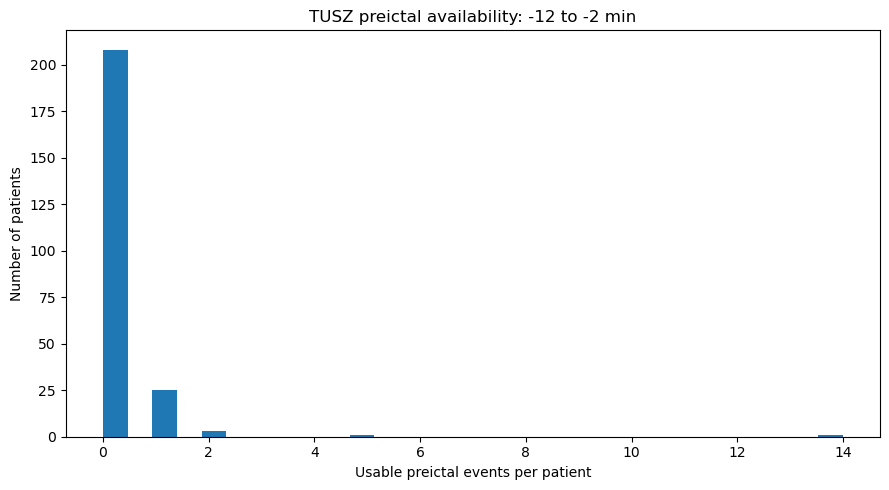

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    eligibility[
        "sop10_sph2_preictal_events"
    ],
    bins=30,
)

ax.set_xlabel(
    "Usable preictal events per patient"
)

ax.set_ylabel("Number of patients")

ax.set_title(
    "TUSZ preictal availability: -12 to -2 min"
)

fig.tight_layout()
plt.show()

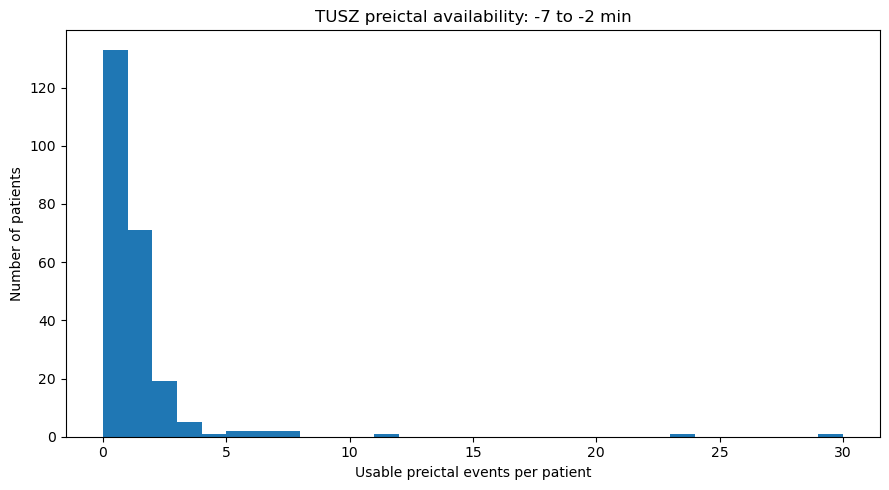

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    eligibility[
        "sop5_sph2_preictal_events"
    ],
    bins=30,
)

ax.set_xlabel(
    "Usable preictal events per patient"
)

ax.set_ylabel("Number of patients")

ax.set_title(
    "TUSZ preictal availability: -7 to -2 min"
)

fig.tight_layout()
plt.show()

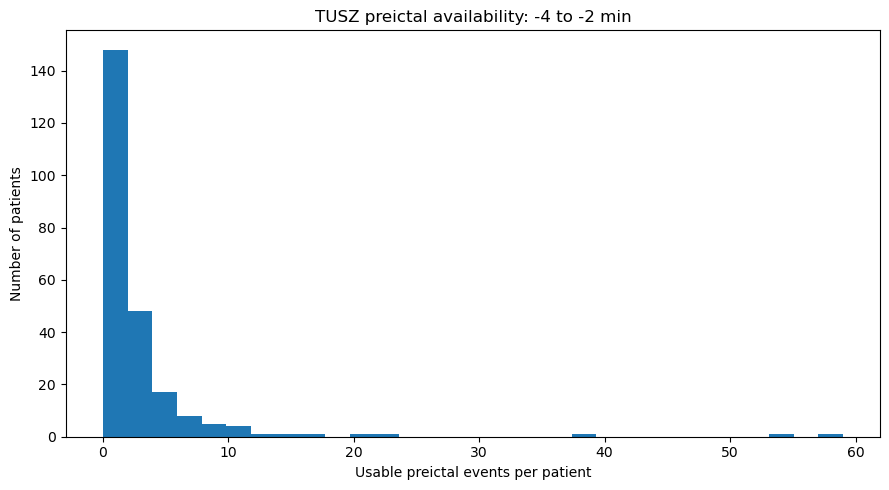

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    eligibility[
        "sop2_sph2_preictal_events"
    ],
    bins=30,
)

ax.set_xlabel(
    "Usable preictal events per patient"
)

ax.set_ylabel("Number of patients")

ax.set_title(
    "TUSZ preictal availability: -4 to -2 min"
)

fig.tight_layout()
plt.show()

## 8. Candidate cohorts before applying the final minimum-data criteria


In [19]:
# ================================================================
# ICTAL CANDIDATES
#
# IMPORTANT:
# Do NOT choose final threshold until we inspect distribution.
# ================================================================

ictal_candidates = eligibility[
    eligibility["ictal_basic_eligible"]
].copy()

ictal_candidates = ictal_candidates.sort_values(
    [
        "ictal_usable_30s",
        "ictal_interictal_30s_model",
    ],
    ascending=False,
)

display(
    ictal_candidates[
        [
            "patient",
            "n_seizures_total",
            "ictal_usable_30s",
            "ictal_interictal_30s_model",
            "ictal_train_interictal",
            "ictal_val_interictal",
            "ictal_test_interictal",
        ]
    ].head(100)
)

,patient,n_seizures_total,ictal_usable_30s,ictal_interictal_30s_model,ictal_train_interictal,ictal_val_interictal,ictal_test_interictal
0,aaaaapks,148,142,200,100,50,50
1,aaaaaqtx,129,123,200,100,50,50
2,aaaaahie,96,95,200,100,50,50
3,aaaaajqo,89,85,200,100,50,50
5,aaaaajru,75,72,200,100,50,50
6,aaaaaovk,69,69,45,22,11,12
7,aaaaardk,60,60,200,100,50,50
8,aaaaabhz,60,60,98,49,24,25
9,aaaaampk,59,56,200,100,50,50
13,aaaaafcf,50,50,157,78,39,40


## 8. Candidate cohorts before applying the final minimum-data criteria


In [20]:
# ================================================================
# BASIC PREICTAL CANDIDATES
#
# At least one usable preictal event
# + structurally valid interictal train/val/test split.
#
# We will choose a stronger minimum event threshold AFTER
# inspecting the distributions.
# ================================================================

for cfg in PREICTAL_CONFIGS:

    name = cfg["name"]

    candidates = eligibility[
        eligibility[
            f"{name}_basic_eligible"
        ]
    ].copy()

    candidates = candidates.sort_values(
        f"{name}_preictal_events",
        ascending=False,
    )

    print()
    print("=" * 80)
    print(name)
    print("=" * 80)

    display(
        candidates[
            [
                "patient",
                "n_seizures_total",
                f"{name}_preictal_events",
                f"{name}_interictal_model",
                f"{name}_train_interictal",
                f"{name}_val_interictal",
                f"{name}_test_interictal",
            ]
        ].head(100)
    )


sop10_sph2


,patient,n_seizures_total,sop10_sph2_preictal_events,sop10_sph2_interictal_model,sop10_sph2_train_interictal,sop10_sph2_val_interictal,sop10_sph2_test_interictal
2,aaaaahie,96,14,200,100,50,50
46,aaaaarsp,15,5,73,36,18,19
17,aaaaardf,28,2,17,8,4,5
9,aaaaampk,59,1,11,6,3,2
7,aaaaardk,60,1,16,8,4,4
25,aaaaaskf,24,1,65,32,16,17
80,aaaaarcs,8,1,12,6,3,3
81,aaaaatgc,8,1,22,11,6,5
88,aaaaaopm,8,1,28,14,7,7
96,aaaaasip,7,1,13,6,3,4



sop5_sph2


,patient,n_seizures_total,sop5_sph2_preictal_events,sop5_sph2_interictal_model,sop5_sph2_train_interictal,sop5_sph2_val_interictal,sop5_sph2_test_interictal
2,aaaaahie,96,30,200,100,50,50
9,aaaaampk,59,23,45,22,11,12
7,aaaaardk,60,11,45,22,11,12
21,aaaaanme,26,7,200,100,50,50
46,aaaaarsp,15,7,158,79,40,39
87,aaaaaoys,8,6,23,12,6,5
17,aaaaardf,28,6,48,24,12,12
24,aaaaamqq,25,5,184,92,46,46
34,aaaaarnq,21,5,7,4,2,1
48,aaaaalfs,15,4,5,2,1,2



sop2_sph2


,patient,n_seizures_total,sop2_sph2_preictal_events,sop2_sph2_interictal_model,sop2_sph2_train_interictal,sop2_sph2_val_interictal,sop2_sph2_test_interictal
2,aaaaahie,96,59,200,100,50,50
7,aaaaardk,60,54,170,85,42,43
9,aaaaampk,59,39,127,64,32,31
17,aaaaardf,28,22,142,71,36,35
21,aaaaanme,26,20,200,100,50,50
14,aaaaaqkb,41,16,84,42,21,21
20,aaaaatez,26,15,45,22,11,12
56,aaaaaqld,14,13,118,59,30,29
46,aaaaarsp,15,11,200,100,50,50
3,aaaaajqo,89,10,200,100,50,50


In [21]:
print(threshold_table)

   configuration  SOP_min  SPH_min preictal_interval  minimum_preictal_events  \
0     sop10_sph2     10.0      2.0     -12 to -2 min                        1   
1     sop10_sph2     10.0      2.0     -12 to -2 min                        2   
2     sop10_sph2     10.0      2.0     -12 to -2 min                        3   
3     sop10_sph2     10.0      2.0     -12 to -2 min                        5   
4     sop10_sph2     10.0      2.0     -12 to -2 min                        8   
5     sop10_sph2     10.0      2.0     -12 to -2 min                       10   
6     sop10_sph2     10.0      2.0     -12 to -2 min                       15   
7     sop10_sph2     10.0      2.0     -12 to -2 min                       20   
8      sop5_sph2      5.0      2.0      -7 to -2 min                        1   
9      sop5_sph2      5.0      2.0      -7 to -2 min                        2   
10     sop5_sph2      5.0      2.0      -7 to -2 min                        3   
11     sop5_sph2      5.0   

In [22]:
print(comparison)

      patient  n_seizures_total  sop10_sph2_preictal_events  \
2    aaaaahie                96                          14   
7    aaaaardk                60                           1   
9    aaaaampk                59                           1   
17   aaaaardf                28                           2   
21   aaaaanme                26                           0   
..        ...               ...                         ...   
225  aaaaanrc                 1                           0   
223  aaaaaocy                 1                           0   
232  aaaaaqro                 1                           0   
233  aaaaaqtl                 1                           0   
234  aaaaappv                 1                           0   

     sop5_sph2_preictal_events  sop2_sph2_preictal_events  
2                           30                         59  
7                           11                         54  
9                           23                         39  
17 

In [23]:
for min_ictal in [1, 3, 5, 10, 15, 20, 30]:
    for min_each_split in [1, 3, 5, 10]:
        good = eligibility[
            (eligibility["ictal_usable_30s"] >= min_ictal)
            &
            (eligibility["ictal_train_interictal"] >= min_each_split)
            &
            (eligibility["ictal_val_interictal"] >= min_each_split)
            &
            (eligibility["ictal_test_interictal"] >= min_each_split)
        ]

        print(
            f"ictal >= {min_ictal:2d}, "
            f"interictal train/val/test >= {min_each_split:2d} each: "
            f"{len(good)} patients"
        )
    print()

ictal >=  1, interictal train/val/test >=  1 each: 229 patients
ictal >=  1, interictal train/val/test >=  3 each: 222 patients
ictal >=  1, interictal train/val/test >=  5 each: 217 patients
ictal >=  1, interictal train/val/test >= 10 each: 185 patients

ictal >=  3, interictal train/val/test >=  1 each: 139 patients
ictal >=  3, interictal train/val/test >=  3 each: 133 patients
ictal >=  3, interictal train/val/test >=  5 each: 130 patients
ictal >=  3, interictal train/val/test >= 10 each: 121 patients

ictal >=  5, interictal train/val/test >=  1 each: 109 patients
ictal >=  5, interictal train/val/test >=  3 each: 104 patients
ictal >=  5, interictal train/val/test >=  5 each: 104 patients
ictal >=  5, interictal train/val/test >= 10 each: 97 patients

ictal >= 10, interictal train/val/test >=  1 each: 72 patients
ictal >= 10, interictal train/val/test >=  3 each: 69 patients
ictal >= 10, interictal train/val/test >=  5 each: 69 patients
ictal >= 10, interictal train/val/test >=

In [24]:
for min_preictal in [1, 2, 3, 5, 8, 10, 15, 20]:
    for min_each_split in [1, 2, 3, 5, 10]:
        good = eligibility[
            (eligibility["sop2_sph2_preictal_events"] >= min_preictal)
            &
            (eligibility["sop2_sph2_train_interictal"] >= min_each_split)
            &
            (eligibility["sop2_sph2_val_interictal"] >= min_each_split)
            &
            (eligibility["sop2_sph2_test_interictal"] >= min_each_split)
        ]

        print(
            f"preictal >= {min_preictal:2d}, "
            f"interictal train/val/test >= {min_each_split:2d} each: "
            f"{len(good)} patients"
        )
    print()

preictal >=  1, interictal train/val/test >=  1 each: 149 patients
preictal >=  1, interictal train/val/test >=  2 each: 127 patients
preictal >=  1, interictal train/val/test >=  3 each: 114 patients
preictal >=  1, interictal train/val/test >=  5 each: 102 patients
preictal >=  1, interictal train/val/test >= 10 each: 87 patients

preictal >=  2, interictal train/val/test >=  1 each: 85 patients
preictal >=  2, interictal train/val/test >=  2 each: 81 patients
preictal >=  2, interictal train/val/test >=  3 each: 75 patients
preictal >=  2, interictal train/val/test >=  5 each: 71 patients
preictal >=  2, interictal train/val/test >= 10 each: 66 patients

preictal >=  3, interictal train/val/test >=  1 each: 64 patients
preictal >=  3, interictal train/val/test >=  2 each: 62 patients
preictal >=  3, interictal train/val/test >=  3 each: 58 patients
preictal >=  3, interictal train/val/test >=  5 each: 56 patients
preictal >=  3, interictal train/val/test >= 10 each: 53 patients

pre

In [25]:
cols = [
    "patient",
    "ictal_usable_30s",
    "ictal_train_interictal",
    "ictal_val_interictal",
    "ictal_test_interictal",
    "sop2_sph2_preictal_events",
    "sop2_sph2_train_interictal",
    "sop2_sph2_val_interictal",
    "sop2_sph2_test_interictal",
]

display(
    eligibility[cols]
    .sort_values(
        ["sop2_sph2_preictal_events", "sop2_sph2_train_interictal"],
        ascending=False
    )
    .head(100)
)

,patient,ictal_usable_30s,ictal_train_interictal,ictal_val_interictal,ictal_test_interictal,sop2_sph2_preictal_events,sop2_sph2_train_interictal,sop2_sph2_val_interictal,sop2_sph2_test_interictal
2,aaaaahie,95,100,50,50,59,100,50,50
7,aaaaardk,60,100,50,50,54,85,42,43
9,aaaaampk,56,100,50,50,39,64,32,31
17,aaaaardf,28,100,50,50,22,71,36,35
21,aaaaanme,26,100,50,50,20,100,50,50
14,aaaaaqkb,41,100,50,50,16,42,21,21
20,aaaaatez,25,100,50,50,15,22,11,12
56,aaaaaqld,14,100,50,50,13,59,30,29
46,aaaaarsp,15,100,50,50,11,100,50,50
3,aaaaajqo,85,100,50,50,10,100,50,50


## 9. Final outcome-independent cohort definitions

The following criteria are fixed before running the forecasting model.

**Ictal external validation**

- $\geq 10$ usable 30-s seizure-onset windows;
- $\geq 20$ clean 30-s interictal training windows;
- $\geq 10$ clean 30-s validation windows;
- $\geq 10$ clean 30-s held-out test windows.

**Exploratory preictal warning ($-4$ to $-2$ min)**

- $\geq 5$ usable preictal events;
- $\geq 20$ clean 2-min interictal training sequences;
- $\geq 10$ clean 2-min validation sequences;
- $\geq 10$ clean 2-min held-out test sequences.

The two cohorts are selected independently. Their intersection is also saved for transparency, but the intersection is not used as a requirement for either primary analysis.


In [26]:
# ================================================================
# FINAL FIXED ELIGIBILITY CRITERIA
# ================================================================

ICTAL_MIN_EVENTS = 10
ICTAL_MIN_TRAIN = 20
ICTAL_MIN_VAL = 10
ICTAL_MIN_TEST = 10

PREICTAL_CONFIG_FINAL = "sop2_sph2"   # -4 to -2 min
PREICTAL_MIN_EVENTS = 5
PREICTAL_MIN_TRAIN = 20
PREICTAL_MIN_VAL = 10
PREICTAL_MIN_TEST = 10

ictal_mask = (
    (eligibility["ictal_usable_30s"] >= ICTAL_MIN_EVENTS)
    & (eligibility["ictal_train_interictal"] >= ICTAL_MIN_TRAIN)
    & (eligibility["ictal_val_interictal"] >= ICTAL_MIN_VAL)
    & (eligibility["ictal_test_interictal"] >= ICTAL_MIN_TEST)
)

preictal_mask = (
    (eligibility[f"{PREICTAL_CONFIG_FINAL}_preictal_events"] >= PREICTAL_MIN_EVENTS)
    & (eligibility[f"{PREICTAL_CONFIG_FINAL}_train_interictal"] >= PREICTAL_MIN_TRAIN)
    & (eligibility[f"{PREICTAL_CONFIG_FINAL}_val_interictal"] >= PREICTAL_MIN_VAL)
    & (eligibility[f"{PREICTAL_CONFIG_FINAL}_test_interictal"] >= PREICTAL_MIN_TEST)
)

ictal_selected = (
    eligibility.loc[ictal_mask].copy()
    .sort_values(["ictal_usable_30s", "patient"], ascending=[False, True])
)

preictal_selected = (
    eligibility.loc[preictal_mask].copy()
    .sort_values([f"{PREICTAL_CONFIG_FINAL}_preictal_events", "patient"], ascending=[False, True])
)

ictal_ids = set(ictal_selected["patient"])
preictal_ids = set(preictal_selected["patient"])
overlap_ids = sorted(ictal_ids & preictal_ids)

print(f"Final ictal cohort:     {len(ictal_selected)} patients")
print(f"Final preictal cohort:  {len(preictal_selected)} patients")
print(f"Overlap:                {len(overlap_ids)} patients")
print(f"Ictal only:             {len(ictal_ids - preictal_ids)} patients")
print(f"Preictal only:          {len(preictal_ids - ictal_ids)} patients")


Final ictal cohort:     63 patients
Final preictal cohort:  31 patients
Overlap:                22 patients
Ictal only:             41 patients
Preictal only:          9 patients


In [27]:
# ================================================================
# DISPLAY AND SAVE FINAL COHORTS
# ================================================================

ictal_cols = [
    "patient", "n_seizures_total", "ictal_usable_30s",
    "ictal_train_interictal", "ictal_val_interictal",
    "ictal_test_interictal",
]

preictal_cols = [
    "patient", "n_seizures_total",
    "sop2_sph2_preictal_events",
    "sop2_sph2_train_interictal",
    "sop2_sph2_val_interictal",
    "sop2_sph2_test_interictal",
]

print("ICTAL EXTERNAL-VALIDATION COHORT")
display(ictal_selected[ictal_cols].reset_index(drop=True))

print("PREICTAL EXPLORATORY COHORT (-4 TO -2 MIN)")
display(preictal_selected[preictal_cols].reset_index(drop=True))

ictal_selected[ictal_cols].to_csv(
    OUT_DIR / "final_ictal_patient_cohort.csv", index=False
)
preictal_selected[preictal_cols].to_csv(
    OUT_DIR / "final_preictal_4to2_patient_cohort.csv", index=False
)

pd.DataFrame({"patient": overlap_ids}).to_csv(
    OUT_DIR / "ictal_preictal_cohort_overlap.csv", index=False
)

print("\nIctal patient IDs:")
print(", ".join(ictal_selected["patient"].tolist()))
print("\nPreictal patient IDs:")
print(", ".join(preictal_selected["patient"].tolist()))
print("\nPatients satisfying BOTH criteria:")
print(", ".join(overlap_ids))


ICTAL EXTERNAL-VALIDATION COHORT


,patient,n_seizures_total,ictal_usable_30s,ictal_train_interictal,ictal_val_interictal,ictal_test_interictal
0,aaaaapks,148,142,100,50,50
1,aaaaaqtx,129,123,100,50,50
2,aaaaahie,96,95,100,50,50
3,aaaaajqo,89,85,100,50,50
4,aaaaajru,75,72,100,50,50
5,aaaaaovk,69,69,22,11,12
6,aaaaabhz,60,60,49,24,25
7,aaaaardk,60,60,100,50,50
8,aaaaampk,59,56,100,50,50
9,aaaaafcf,50,50,78,39,40


PREICTAL EXPLORATORY COHORT (-4 TO -2 MIN)


,patient,n_seizures_total,sop2_sph2_preictal_events,sop2_sph2_train_interictal,sop2_sph2_val_interictal,sop2_sph2_test_interictal
0,aaaaahie,96,59,100,50,50
1,aaaaardk,60,54,85,42,43
2,aaaaampk,59,39,64,32,31
3,aaaaardf,28,22,71,36,35
4,aaaaanme,26,20,100,50,50
5,aaaaaqkb,41,16,42,21,21
6,aaaaatez,26,15,22,11,12
7,aaaaaqld,14,13,59,30,29
8,aaaaarsp,15,11,100,50,50
9,aaaaajqo,89,10,100,50,50



Ictal patient IDs:
aaaaapks, aaaaaqtx, aaaaahie, aaaaajqo, aaaaajru, aaaaaovk, aaaaabhz, aaaaardk, aaaaampk, aaaaafcf, aaaaaprj, aaaaaqkb, aaaaarsm, aaaaardf, aaaaacqc, aaaaaedy, aaaaaelb, aaaaaghb, aaaaanme, aaaaaksg, aaaaamqq, aaaaatez, aaaaaskf, aaaaates, aaaaafjw, aaaaarpv, aaaaatjh, aaaaadkj, aaaaaizz, aaaaarnq, aaaaaooo, aaaaaroo, aaaaaasy, aaaaakkm, aaaaajsl, aaaaakoe, aaaaamoa, aaaaamod, aaaaaasf, aaaaamhj, aaaaaqvx, aaaaalfs, aaaaamta, aaaaaqbb, aaaaarsp, aaaaaswc, aaaaapas, aaaaaqld, aaaaasgd, aaaaammu, aaaaamnk, aaaaaqtw, aaaaajfq, aaaaaccj, aaaaaqrs, aaaaatds, aaaaaarq, aaaaaayf, aaaaajax, aaaaajmr, aaaaaksh, aaaaaron, aaaaasoc

Preictal patient IDs:
aaaaahie, aaaaardk, aaaaampk, aaaaardf, aaaaanme, aaaaaqkb, aaaaatez, aaaaaqld, aaaaarsp, aaaaajqo, aaaaamqq, aaaaajru, aaaaammu, aaaaaron, aaaaates, aaaaaoek, aaaaaoys, aaaaaroo, aaaaarpv, aaaaasgd, aaaaajfq, aaaaaqrs, aaaaatlp, aaaaaool, aaaaapas, aaaaaqkh, aaaaarcs, aaaaarpu, aaaaarsm, aaaaasip, aaaaasme

Patients satisfyin

## 10. Supplementary eligibility figures

These figures document cohort construction rather than model performance. They are appropriate for the Supplementary Material because they show why the final TUSZ cohorts and short preictal definition were chosen without using forecasting outcomes.

The figures are saved as both PNG (300 dpi) and PDF.


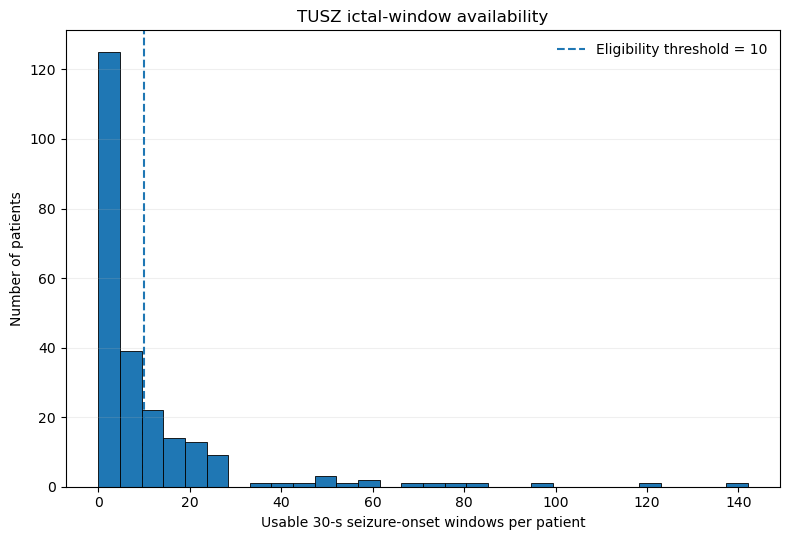

In [28]:
# ================================================================
# FIGURE Sx: ICTAL EVENT AVAILABILITY
# ================================================================

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.hist(eligibility["ictal_usable_30s"], bins=30, edgecolor="black", linewidth=0.6)
ax.axvline(ICTAL_MIN_EVENTS, linestyle="--", linewidth=1.5, label=f"Eligibility threshold = {ICTAL_MIN_EVENTS}")
ax.set_xlabel("Usable 30-s seizure-onset windows per patient")
ax.set_ylabel("Number of patients")
ax.set_title("TUSZ ictal-window availability")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "supp_tusz_ictal_window_availability.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "supp_tusz_ictal_window_availability.pdf", bbox_inches="tight")
plt.show()


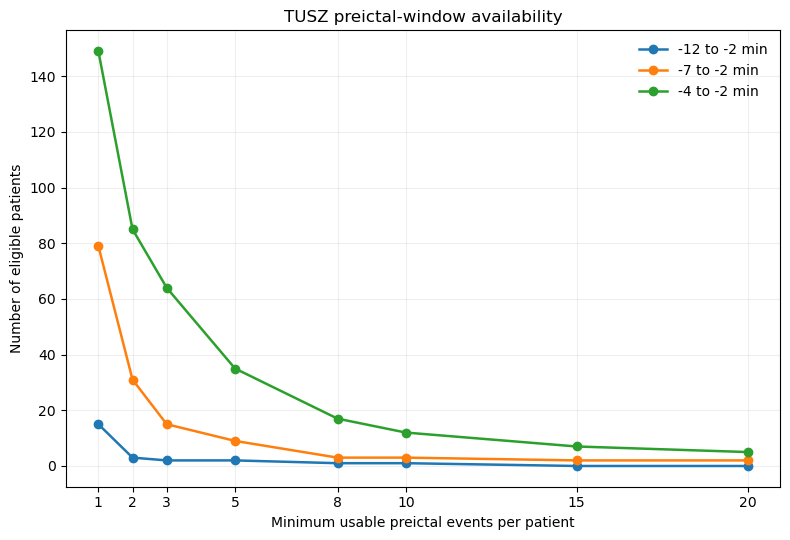

In [29]:
# ================================================================
# FIGURE Sx: PREICTAL WINDOW AVAILABILITY ACROSS DEFINITIONS
# ================================================================

thresholds = np.array([1, 2, 3, 5, 8, 10, 15, 20])

fig, ax = plt.subplots(figsize=(8, 5.5))

for cfg in PREICTAL_CONFIGS:
    name = cfg["name"]
    sop = cfg["sop_min"]
    sph = cfg["sph_min"]
    label = f"-{sop+sph:g} to -{sph:g} min"

    counts = []
    for n in thresholds:
        mask = (
            (eligibility[f"{name}_preictal_events"] >= n)
            & (eligibility[f"{name}_train_interictal"] >= 1)
            & (eligibility[f"{name}_val_interictal"] >= 1)
            & (eligibility[f"{name}_test_interictal"] >= 1)
        )
        counts.append(int(mask.sum()))

    ax.plot(thresholds, counts, marker="o", linewidth=1.8, label=label)

ax.set_xlabel("Minimum usable preictal events per patient")
ax.set_ylabel("Number of eligible patients")
ax.set_title("TUSZ preictal-window availability")
ax.set_xticks(thresholds)
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "supp_tusz_preictal_window_availability.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "supp_tusz_preictal_window_availability.pdf", bbox_inches="tight")
plt.show()


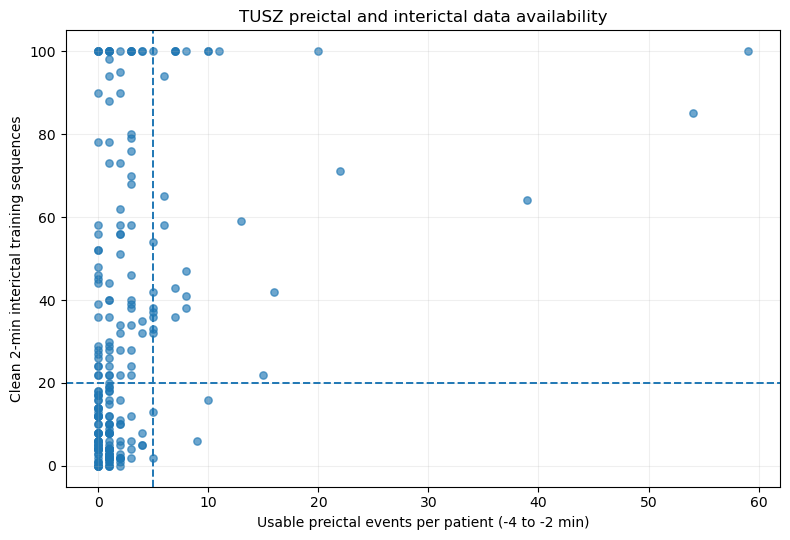

In [30]:
# ================================================================
# FIGURE Sx: JOINT POSITIVE-EVENT AND INTERICTAL AVAILABILITY
# Final exploratory preictal configuration (-4 to -2 min)
# ================================================================

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    eligibility["sop2_sph2_preictal_events"],
    eligibility["sop2_sph2_train_interictal"],
    s=28,
    alpha=0.65,
)
ax.axvline(PREICTAL_MIN_EVENTS, linestyle="--", linewidth=1.4)
ax.axhline(PREICTAL_MIN_TRAIN, linestyle="--", linewidth=1.4)
ax.set_xlabel("Usable preictal events per patient (-4 to -2 min)")
ax.set_ylabel("Clean 2-min interictal training sequences")
ax.set_title("TUSZ preictal and interictal data availability")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "supp_tusz_preictal_joint_availability.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "supp_tusz_preictal_joint_availability.pdf", bbox_inches="tight")
plt.show()


In [31]:
# Patients for the ictal analysis

ictal_final = eligibility[
    (eligibility["ictal_usable_30s"] >= 10)
    & (eligibility["ictal_train_interictal"] >= 20)
    & (eligibility["ictal_val_interictal"] >= 10)
    & (eligibility["ictal_test_interictal"] >= 10)
]["patient"].tolist()

print(len(ictal_final))
print(ictal_final)

63
['aaaaapks', 'aaaaaqtx', 'aaaaahie', 'aaaaajqo', 'aaaaajru', 'aaaaaovk', 'aaaaardk', 'aaaaabhz', 'aaaaampk', 'aaaaaprj', 'aaaaafcf', 'aaaaaqkb', 'aaaaarsm', 'aaaaaedy', 'aaaaardf', 'aaaaaelb', 'aaaaacqc', 'aaaaatez', 'aaaaanme', 'aaaaaghb', 'aaaaaksg', 'aaaaamqq', 'aaaaaskf', 'aaaaatjh', 'aaaaates', 'aaaaarpv', 'aaaaaizz', 'aaaaafjw', 'aaaaaooo', 'aaaaadkj', 'aaaaarnq', 'aaaaaroo', 'aaaaaasy', 'aaaaajsl', 'aaaaakkm', 'aaaaakoe', 'aaaaamod', 'aaaaaasf', 'aaaaamoa', 'aaaaaqvx', 'aaaaamhj', 'aaaaarsp', 'aaaaaswc', 'aaaaalfs', 'aaaaamta', 'aaaaaqbb', 'aaaaaqtw', 'aaaaaqld', 'aaaaammu', 'aaaaasgd', 'aaaaapas', 'aaaaamnk', 'aaaaajfq', 'aaaaatds', 'aaaaaksh', 'aaaaaccj', 'aaaaaqrs', 'aaaaaron', 'aaaaasoc', 'aaaaajax', 'aaaaaayf', 'aaaaaarq', 'aaaaajmr']


In [32]:
# Patients for the preictal analysis

preictal_final = eligibility[
    (eligibility["sop2_sph2_preictal_events"] >= 5)
    & (eligibility["sop2_sph2_train_interictal"] >= 20)
    & (eligibility["sop2_sph2_val_interictal"] >= 10)
    & (eligibility["sop2_sph2_test_interictal"] >= 10)
]["patient"].tolist()

print(len(preictal_final))
print(preictal_final)

31
['aaaaahie', 'aaaaajqo', 'aaaaajru', 'aaaaardk', 'aaaaampk', 'aaaaaqkb', 'aaaaarsm', 'aaaaardf', 'aaaaatez', 'aaaaanme', 'aaaaamqq', 'aaaaates', 'aaaaarpv', 'aaaaaroo', 'aaaaarsp', 'aaaaaqld', 'aaaaammu', 'aaaaasgd', 'aaaaapas', 'aaaaajfq', 'aaaaaqrs', 'aaaaaron', 'aaaaarcs', 'aaaaaoek', 'aaaaaoys', 'aaaaaqkh', 'aaaaaool', 'aaaaasip', 'aaaaatlp', 'aaaaasme', 'aaaaarpu']


## 11. Reproducibility notes

- Patient eligibility is determined before any forecasting model is fitted.
- Seizure-onset windows require sufficient remaining EEG in the same EDF recording.
- Preictal windows must be fully contained within the corresponding EDF; adjacent EDF files are not concatenated.
- Candidate preictal windows overlapping another annotated seizure are excluded.
- The common 16-channel bipolar representation must be directly available or reconstructable from referential channels.
- Clean interictal windows are counted separately for each experiment because the required sequence duration differs.
- The final ictal and preictal cohorts are saved as CSV files in `tusz_patient_eligibility_analysis/` and should be used unchanged by downstream model scripts.
